# Week 3 — Modelling, Tuning & Interpretability: Airline Passenger Satisfaction

**Course:** MSc Machine Learning · **Team:** Group 1 — Team 22

**Data:** `data/raw/airline_passenger_satisfaction.csv` — `129,880 × 24` → 22 features + target `Satisfaction` (`Satisfied` → 1)

**Protocol:** the Week 2 pipeline `preprocess → select (CappedRFECV, 20 features) → model` with only the `model` step swapped · `random_state=42` everywhere · the same stratified 80/20 split as Week 2 · one shared 5-fold `StratifiedKFold` for every CV score and every search · primary metric ROC-AUC (+ PR-AUC, accuracy, per-class precision / recall / F1) · `X_test` is used only from §9 on, after every model is fixed.

## 1. Team & Week 3 contributions

| Member | Student ID | Role | Week 3 contribution | Sections |
|---|---|---|---|---|
| Arsen Zhexenbiyev | 22MD0361 | Modelling & Deployment Lead | Evaluation framework (`src/airline_fe/modelling.py`): shared CV, metrics, tuning report, comparison table; baseline LR; XGBoost with early stopping (tuning + early-stopping demo); confusion-matrix and SHAP code; model export for Week 4 | §3–4, §7–12 |
| Alisher Toxanbayev | 26MD0376 | Feature Engineer | Intermediate model 1 — search space, tuning, results ⏳ | §5 |
| *TBD* | | | Intermediate model 2 — search space, tuning, results ⏳ | §6 |
| Kamila Muzanbekova | 26MD0368 | Report Lead | Written interpretations of the confusion matrices and all three SHAP plots; report assembly and PDF ⏳ | §10–11 |

⏳ = slot left for the owner. Each slot is marked **SLOT** below; the notebook runs end to end with the slots switched off, and every model added in a slot flows into the tuning report, the comparison table, the confusion matrices and the SHAP model choice automatically.

## 2. Setup, load & split

In [1]:
# Cell 1 — paths, imports & constants (same layout as Week 2)
import io
import os
import sys
import tempfile
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import sklearn
import xgboost
from IPython.display import display
from sklearn import set_config
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA_PATH = ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv"
FIG_DIR = ROOT / "reports" / "figures"
REPORT_DIR = ROOT / "reports"
MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
# Cache for the fitted preprocess + select steps (see §3). Outside the repo and OneDrive.
CACHE_DIR = Path(os.environ.get("AIRLINE_FE_CACHE", Path(tempfile.gettempdir()) / "airline_fe_cache"))

from airline_fe.config import ID_COL, LIKERT, RANDOM_STATE, TARGET
from airline_fe.evaluation import CV
from airline_fe.modelling import (
    CLASS_NAMES, METRICS, PRIMARY, SCORING, EarlyStoppingXGBClassifier, best_model_name,
    comparison_table, cv_table, evaluate_untuned, make_model_pipeline, pick_shap_cases,
    plot_confusion_matrices, plot_early_stopping, predict_test, shap_explanation,
    to_raw_units, tune_model, tuning_report,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | shap {shap.__version__}")

Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | xgboost 3.2.0 | shap 0.54.1


In [2]:
# Load, drop the ID key, map the target, and split exactly as in Week 2
FEATURE_COLS = ["Gender", "Age", "Customer Type", "Type of Travel", "Class",
                "Flight Distance", "Departure Delay", "Arrival Delay", *LIKERT]

df = pd.read_csv(DATA_PATH)
assert df.shape == (129_880, 24), f"unexpected shape {df.shape}"
X = df.drop(columns=[ID_COL, TARGET])
y = (df[TARGET] == "Satisfied").astype(int).rename(TARGET)
assert list(X.columns) == FEATURE_COLS
assert set(X.columns[X.isna().any()]) <= {"Arrival Delay"}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
assert (len(X_train), len(X_test)) == (103_904, 25_976)
del df, X, y
print(f"X_train {X_train.shape} | X_test {X_test.shape} | "
      f"positive rate train {y_train.mean():.4f} / test {y_test.mean():.4f}")

X_train (103904, 22) | X_test (25976, 22) | positive rate train 0.4345 / test 0.4345


## 3. Shared protocol: pipeline, folds, metrics

- **One pipeline for every model.** `make_model_pipeline(estimator)` returns the Week 2 `build_pipeline(selector=FINAL_SELECTOR, estimator=…)`: the same `ColumnTransformer` branches and the same `CappedRFECV` selector (Method B, the Week 2 winner, capped at 20 features), with only the `model` step changed. Every model is therefore fitted and tuned **inside** the pipeline, and selection is refitted in every training fold.
- **One set of folds.** `CV = StratifiedKFold(5, shuffle=True, random_state=42)` from Week 2 is used for the baseline, the pre-tuning scores and every search. Score differences between models are paired.
- **Metrics.** Accuracy, precision / recall / F1 for each class (`_1` = Satisfied, `_0` = Neutral or Dissatisfied), ROC-AUC and PR-AUC. Searches refit on ROC-AUC.
- **Caching.** `CappedRFECV` takes ~30 s per fit. The pipeline's `memory` caches the fitted `preprocess` and `select` steps, keyed on their parameters and the exact fold rows, so selection runs once per fold instead of once per search candidate. The cache changes no score, only the runtime.

In [3]:
print(f"CV      : {CV}")
print(f"Scoring : {list(SCORING)}")
print(f"Cache   : {CACHE_DIR}")
set_config(display="diagram")
make_model_pipeline(memory=CACHE_DIR)

CV      : StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Scoring : ['accuracy', 'precision_1', 'recall_1', 'f1_1', 'precision_0', 'recall_0', 'f1_0', 'roc_auc', 'pr_auc']
Cache   : C:\Users\zhexa\AppData\Local\Temp\airline_fe_cache


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('select', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'C:\\Users\\zhexa\\AppD...\Temp\\airline_fe_cache'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('class_ord', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: 

## 4. Baseline — Logistic Regression

The baseline is `LogisticRegression` inside the Week 2 pipeline with default hyperparameters, except `max_iter=1000` (default 100 does not converge on 20 features; Week 1 deviation 6) and `random_state=42`. It is the benchmark every tuned model must beat. Because it is the same pipeline on the same folds, its CV ROC-AUC must reproduce the Week 2 S5b row.

In [4]:
results = {}   # name -> result dict; every later section reads from here

BASELINE = "Logistic Regression (baseline)"
results[BASELINE] = evaluate_untuned(BASELINE, make_model_pipeline(memory=CACHE_DIR), X_train, y_train)

week2 = pd.read_csv(REPORT_DIR / "week2_cv_log.csv").set_index("step")
w2_auc, w3_auc = week2.loc["S5b", "roc_auc_mean"], results[BASELINE]["cv"]["roc_auc"][0]
print(f"CV ROC-AUC: Week 2 S5b {w2_auc:.6f} | Week 3 baseline {w3_auc:.6f}")
assert abs(w2_auc - w3_auc) < 1e-4, "baseline does not reproduce the Week 2 pipeline"
display(cv_table({BASELINE: results[BASELINE]}))

CV ROC-AUC: Week 2 S5b 0.964447 | Week 3 baseline 0.964447


,accuracy,precision_1,recall_1,f1_1,precision_0,recall_0,f1_0,roc_auc,pr_auc
Logistic Regression (baseline),0.9019 ± 0.0017,0.8889 ± 0.0024,0.8849 ± 0.0028,0.8869 ± 0.0020,0.9119 ± 0.0020,0.9150 ± 0.0021,0.9134 ± 0.0015,0.9644 ± 0.0004,0.9569 ± 0.0003


**Result.** The baseline reproduces the Week 2 S5b row exactly (CV ROC-AUC 0.964447): same pipeline, same folds. It reaches ROC-AUC 0.9644 ± 0.0004, PR-AUC 0.9569 and accuracy 0.902, with balanced per-class F1 (0.887 Satisfied, 0.913 Neutral or Dissatisfied). Every other model has to beat these numbers by more than the fold std to justify its extra complexity.

## 5. Intermediate model 1 — **SLOT** · owner: Alisher

Choose one of Random Forest, Gradient Boosting, SVM or ElasticNet (Random Forest suggested), define its search space over `model__*` parameters, and set `RUN_INTERMEDIATE_1 = True`.

`tune_model()` reports everything the rubric asks for: the **pre-tuning CV score** (the model with default parameters on the same folds), the **post-tuning CV score**, the **best parameters** and the **tuning time**. Keep `n_jobs=1` inside the estimator: the search already uses all cores.

Then replace this paragraph with 2–4 sentences: which model, why this search space, and what tuning changed.

In [5]:
# SLOT — Intermediate model 1 (owner: Alisher)
RUN_INTERMEDIATE_1 = False

if RUN_INTERMEDIATE_1:
    from sklearn.ensemble import RandomForestClassifier

    INTER_1 = "Random Forest"
    inter_1_pipe = make_model_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), memory=CACHE_DIR)
    INTER_1_SPACE = {
        # "model__n_estimators": [...],
        # "model__max_depth": [...],
        # "model__min_samples_leaf": [...],
        # "model__max_features": [...],
    }
    results[INTER_1] = tune_model(INTER_1, inter_1_pipe, INTER_1_SPACE, X_train, y_train,
                                  search="random", n_iter=20)
    display(tuning_report({INTER_1: results[INTER_1]}))

## 6. Intermediate model 2 — **SLOT** · owner: *TBD*

Same contract as §5 with a second model from the list (for example `HistGradientBoostingClassifier` or `GradientBoostingClassifier`; `SVC` on ~83k rows per fold is slow). Set `RUN_INTERMEDIATE_2 = True` and replace this paragraph with the 2–4 sentence write-up.

In [6]:
# SLOT — Intermediate model 2 (owner: TBD)
RUN_INTERMEDIATE_2 = False

if RUN_INTERMEDIATE_2:
    INTER_2 = "..."                       # e.g. "Gradient Boosting"
    inter_2_pipe = make_model_pipeline(..., memory=CACHE_DIR)
    INTER_2_SPACE = {
        # "model__...": [...],
    }
    results[INTER_2] = tune_model(INTER_2, inter_2_pipe, INTER_2_SPACE, X_train, y_train,
                                  search="random", n_iter=20)
    display(tuning_report({INTER_2: results[INTER_2]}))

## 7. Advanced model — XGBoost with early stopping

`EarlyStoppingXGBClassifier` (in `src/airline_fe/modelling.py`) is the pipeline's `model` step. In every `fit` it holds out a stratified 10% of **its own training rows**, grows up to 2,000 trees and stops when validation log-loss has not improved for 50 rounds; prediction uses the trees up to the best round. The validation rows come from the training fold only, so early stopping stays leak-free inside CV and inside the search, and every search candidate picks its own number of trees.

The search tunes tree shape, sampling, learning rate and regularisation with `RandomizedSearchCV` (20 candidates × 5 folds). The number of trees is not tuned: early stopping sets it.

In [7]:
XGB = "XGBoost (early stopping)"
xgb_pipe = make_model_pipeline(EarlyStoppingXGBClassifier(), memory=CACHE_DIR)
XGB_SPACE = {
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__min_child_weight": [1, 3, 5, 10],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__reg_lambda": [0.5, 1.0, 2.0, 5.0],
    "model__gamma": [0.0, 0.1, 0.5, 1.0],
}
results[XGB] = tune_model(XGB, xgb_pipe, XGB_SPACE, X_train, y_train, search="random", n_iter=20)
display(tuning_report({XGB: results[XGB]}))

,model,pre-tuning CV ROC-AUC,post-tuning CV ROC-AUC,Δ ROC-AUC,pre-tuning CV PR-AUC,post-tuning CV PR-AUC,candidates,tuning time (s),best params
0,XGBoost (early stopping),0.9942 ± 0.0002,0.9943 ± 0.0002,0.00012,0.9932,0.9933,20,145.6,"{'subsample': 0.9, 'reg_lambda': 5.0, 'min_chi..."


**Result.** With its default settings XGBoost already reaches CV ROC-AUC 0.9942 ± 0.0002, about +0.030 over the baseline. That gain comes from the model class, not from tuning: trees capture interactions a linear model cannot, for example the in-flight Wifi rating mattering differently for business and personal travellers (§11). The 20-candidate search (≈ 2 min with the cache) moves ROC-AUC by only +0.0001, inside one fold std, so tuning confirms the defaults rather than improving them. The chosen candidate uses deeper trees (`max_depth=8`) held in check by stronger L2 regularisation (`reg_lambda=5`) and a split penalty (`gamma=0.1`).

Trees grown: 597 of max 2000 | best iteration: 547 | patience 50


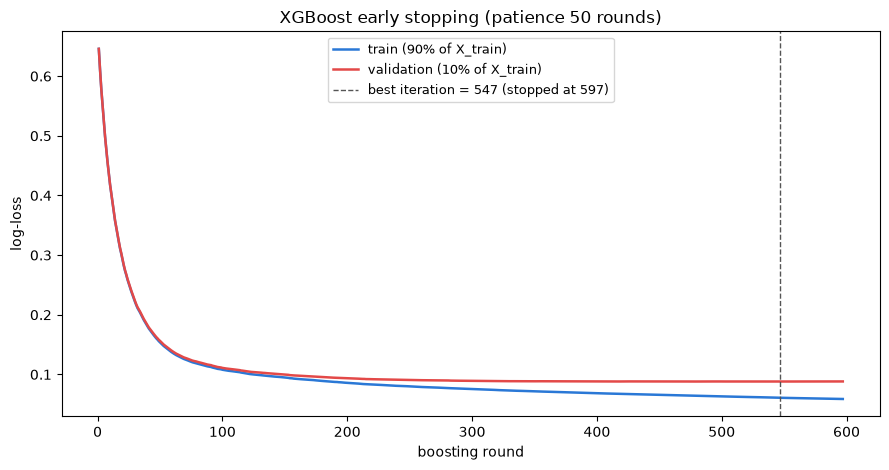

In [8]:
# Early stopping on the refitted best pipeline (fitted on X_train; validation = 10% of X_train)
xgb_step = results[XGB]["estimator"].named_steps["model"]
n_rounds = len(xgb_step.evals_result_["validation_1"]["logloss"])
print(f"Trees grown: {n_rounds} of max {xgb_step.n_estimators} | best iteration: {xgb_step.n_trees_} "
      f"| patience {xgb_step.early_stopping_rounds}")
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_early_stopping(xgb_step, ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "week3_xgb_early_stopping.png", dpi=150, bbox_inches="tight")
plt.show()

**Early stopping.** On the refitted best pipeline, validation log-loss stops improving at round 547; training continued for the 50-round patience and stopped at 597 of a possible 2,000 rounds, and prediction uses the first 547 trees. After that point training loss keeps falling while validation loss is flat: further trees would only fit the training rows. Every CV fold and every search candidate chooses its own stopping round in the same way, on its own training rows.

## 8. Tuning report — every tuned model

One row per tuned model: pre-tuning and post-tuning CV ROC-AUC on the same five folds, the gain, PR-AUC before and after, the number of candidates, the tuning time and the best parameters. The post-tuning score is the best candidate's mean over the folds that selected it, so it is slightly optimistic; the test column in §9 is the unbiased check.

In [9]:
tuning = tuning_report(results)
tuning.to_csv(REPORT_DIR / "week3_tuning_report.csv", index=False)
display(tuning)

,model,pre-tuning CV ROC-AUC,post-tuning CV ROC-AUC,Δ ROC-AUC,pre-tuning CV PR-AUC,post-tuning CV PR-AUC,candidates,tuning time (s),best params
0,XGBoost (early stopping),0.9942 ± 0.0002,0.9943 ± 0.0002,0.00012,0.9932,0.9933,20,145.6,"{'subsample': 0.9, 'reg_lambda': 5.0, 'min_chi..."


## 9. Final comparison — all models × all metrics, CV next to test

From here on `X_test` is used, for the first time. Every model is already fixed (refitted on all of `X_train` with its best parameters); nothing below changes a model. The best model is chosen by **mean CV ROC-AUC**, never by the test score.

In [10]:
preds = predict_test(results, X_test)
comparison = comparison_table(results, preds, y_test)
comparison.to_csv(REPORT_DIR / "week3_model_comparison.csv", float_format="%.6f")

BEST = best_model_name(results)
print(f"Best model by mean CV ROC-AUC: {BEST}\n")

test_cols = [c for c in comparison.columns if c[1] == "test"]
display(comparison.style.format("{:.4f}")
        .highlight_max(subset=test_cols, axis=0, props="font-weight: bold; background-color: #e3eefa"))

Best model by mean CV ROC-AUC: XGBoost (early stopping)



**Result** *(update this paragraph once §5–§6 are filled)*. XGBoost is the best model by mean CV ROC-AUC, so it is the model explained in §11. For both models the test scores sit within about 0.003 of the CV means (XGBoost: ROC-AUC 0.9947 on test vs 0.9943 in CV, accuracy 0.962 vs 0.960), so neither feature selection nor tuning overfitted the folds. Against the baseline, XGBoost cuts test errors from 2,476 to 997 (−60%) and raises accuracy from 0.905 to 0.962.

In [11]:
# Compact view: the headline metrics only
headline = ["roc_auc", "pr_auc", "accuracy", "f1_1", "f1_0"]
compact = pd.DataFrame({
    m: [f"{comparison.loc[n, (m, 'CV mean')]:.4f} ± {comparison.loc[n, (m, 'CV std')]:.4f} | "
        f"{comparison.loc[n, (m, 'test')]:.4f}" for n in comparison.index]
    for m in headline}, index=comparison.index)
compact.columns = [f"{m}  (CV | test)" for m in headline]
display(compact)

,roc_auc (CV | test),pr_auc (CV | test),accuracy (CV | test),f1_1 (CV | test),f1_0 (CV | test)
model,,,,,
Logistic Regression (baseline),0.9644 ± 0.0004 | 0.9657,0.9569 ± 0.0003 | 0.9588,0.9019 ± 0.0017 | 0.9047,0.8869 ± 0.0020 | 0.8903,0.9134 ± 0.0015 | 0.9157
XGBoost (early stopping),0.9943 ± 0.0002 | 0.9947,0.9933 ± 0.0002 | 0.9938,0.9603 ± 0.0007 | 0.9616,0.9536 ± 0.0008 | 0.9552,0.9653 ± 0.0007 | 0.9664


## 10. Confusion matrices (test set)

Each panel is a seaborn heatmap: counts with the share of the **true** row, so the diagonal reads as per-class recall. The table under the plot breaks the best model's errors down by passenger segment, to support the failure-pattern write-up.

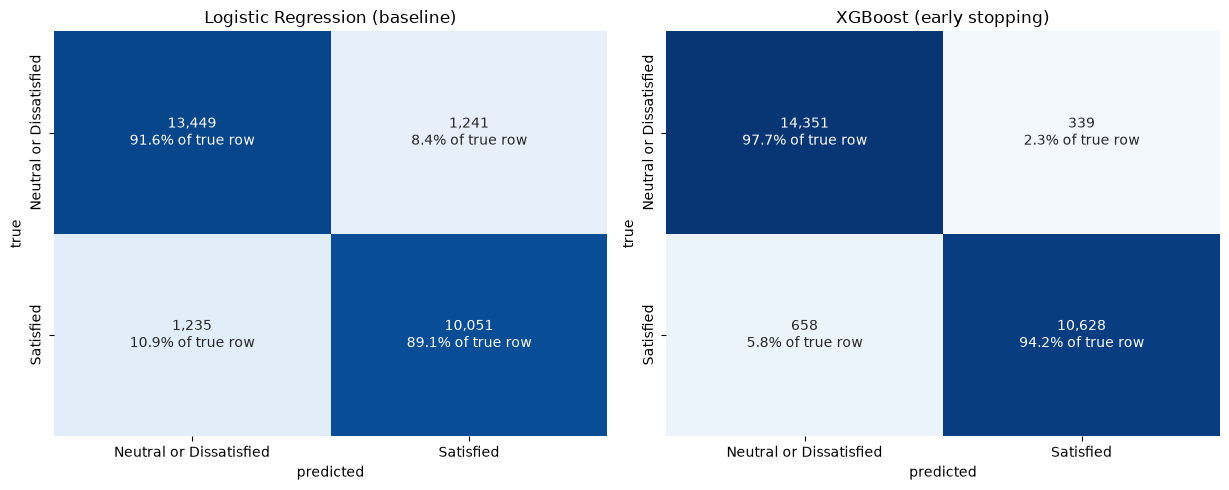

XGBoost (early stopping): 339 false positives, 658 false negatives on 25,976 test passengers


In [12]:
fig = plot_confusion_matrices(preds, y_test)
fig.savefig(FIG_DIR / "week3_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

# Where does the best model fail? Error rates by segment (descriptive, test set only)
y_pred_best, proba_best = preds[BEST]
seg = X_test[["Type of Travel", "Class", "Customer Type"]].assign(
    true=y_test.to_numpy(), pred=y_pred_best,
    false_positive=lambda d: (d.pred == 1) & (d.true == 0),
    false_negative=lambda d: (d.pred == 0) & (d.true == 1))
errors = (seg.groupby(["Type of Travel", "Class"], observed=True)
          .agg(passengers=("true", "size"), satisfied_rate=("true", "mean"),
               FP_rate=("false_positive", "mean"), FN_rate=("false_negative", "mean"))
          .assign(error_rate=lambda d: d.FP_rate + d.FN_rate)
          .sort_values("error_rate", ascending=False))
print(f"{BEST}: {int(seg.false_positive.sum()):,} false positives, "
      f"{int(seg.false_negative.sum()):,} false negatives on {len(seg):,} test passengers")
display(errors.style.format({"passengers": "{:,}", "satisfied_rate": "{:.1%}", "FP_rate": "{:.2%}",
                             "FN_rate": "{:.2%}", "error_rate": "{:.2%}"}))

**SLOT — interpretation · owner: Kamila.** Discuss the specific failure patterns: which error type dominates (false "Satisfied" or false "Neutral or Dissatisfied"), in which segments the error rate is highest (table above), and why those passengers are hard to classify (for example, mixed ratings or segments where the satisfied rate is close to 50%). Compare the baseline's and the best model's panels.

## 11. SHAP analysis of the best model

SHAP values are computed for the best model's `model` step on rows passed through its fitted `preprocess → select` head, so each value belongs to one of the 20 named model features. For tree models they are in **log-odds of "Satisfied"**: positive pushes towards Satisfied, negative towards Neutral or Dissatisfied. Feature values are shown in the passenger's own units (ratings 0–5, delay in minutes); SHAP values are unchanged by that.

The global plot uses a seeded 2,000-row sample of `X_test` (explanation only, nothing is fitted).

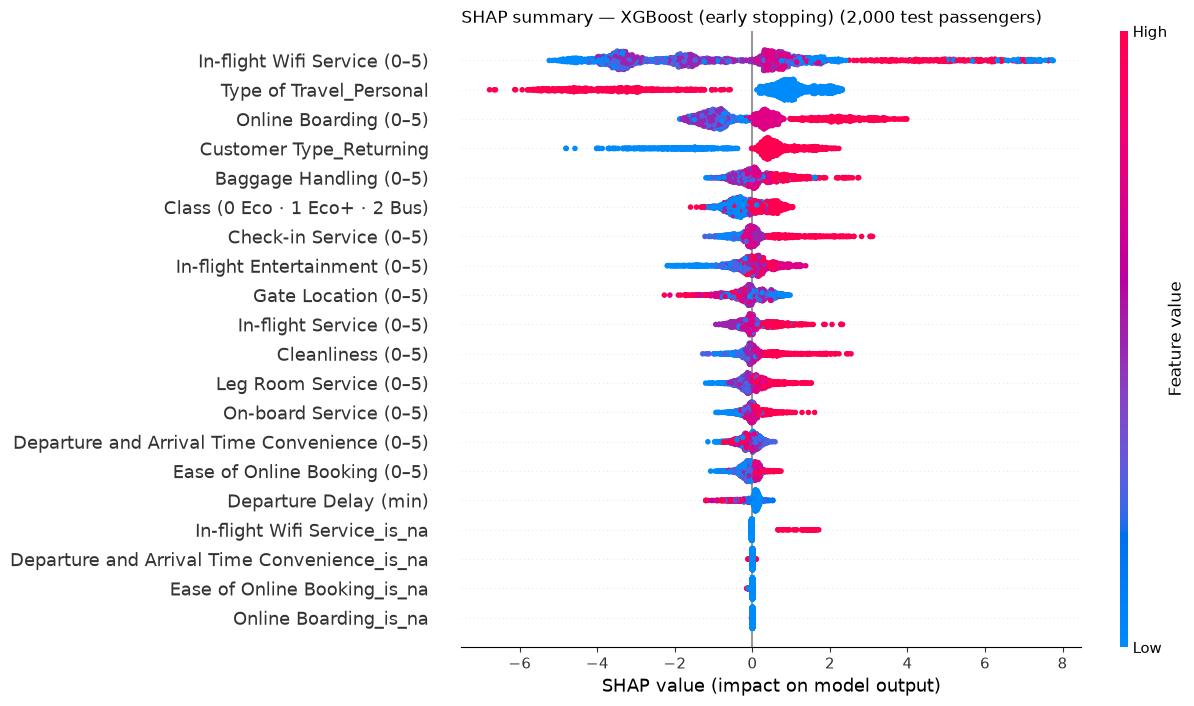

Mean |SHAP| (log-odds), top 8:
In-flight Wifi Service (0–5)      2.423
Type of Travel_Personal           1.889
Online Boarding (0–5)             1.067
Customer Type_Returning           0.906
Baggage Handling (0–5)            0.422
Class (0 Eco · 1 Eco+ · 2 Bus)    0.401
Check-in Service (0–5)            0.362
In-flight Entertainment (0–5)     0.358


In [13]:
best_pipe = results[BEST]["estimator"]
X_shap = X_test.sample(2_000, random_state=RANDOM_STATE)
expl_global = to_raw_units(shap_explanation(best_pipe, X_shap, X_background=X_train), X_shap)

plt.figure()
shap.plots.beeswarm(expl_global, max_display=20, show=False, plot_size=(10, 8))
plt.title(f"SHAP summary — {BEST} (2,000 test passengers)", loc="left")
plt.savefig(FIG_DIR / "week3_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

mean_abs = (pd.Series(np.abs(expl_global.values).mean(axis=0), index=expl_global.feature_names)
            .sort_values(ascending=False))
print("Mean |SHAP| (log-odds), top 8:")
print(mean_abs.head(8).round(3).to_string())

**SLOT — interpretation · owner: Kamila.** In plain language and in airline terms: which experiences drive satisfaction most, in which direction (colour = rating / value), and what that means for the airline (for example, what a low in-flight Wifi or online boarding rating does to a passenger's odds). Link to SQ2: how `Type of Travel_Personal` and `Class` shift the prediction. Avoid purely statistical wording such as "feature X has a high SHAP value".

In [14]:
# Pick the two cases on the full test set: a typical correct prediction and the most confident error
i_right, i_wrong = pick_shap_cases(y_test, y_pred_best, proba_best)
X_cases = X_test.iloc[[i_right, i_wrong]]
expl_cases = to_raw_units(shap_explanation(best_pipe, X_cases, X_background=X_train), X_cases)

cases = X_cases[["Type of Travel", "Class", "Customer Type", "Departure Delay", *LIKERT]].T
cases.columns = ["correct case", "incorrect case"]
for col, i in zip(cases.columns, (i_right, i_wrong)):
    print(f"{col:>15}: true = {CLASS_NAMES[y_test.iloc[i]]:<24} "
          f"predicted = {CLASS_NAMES[y_pred_best[i]]:<24} P(Satisfied) = {proba_best[i]:.3f}")
display(cases)

   correct case: true = Satisfied                predicted = Satisfied                P(Satisfied) = 0.999
 incorrect case: true = Satisfied                predicted = Neutral or Dissatisfied  P(Satisfied) = 0.005


,correct case,incorrect case
Type of Travel,Business,Business
Class,Business,Business
Customer Type,Returning,First-time
Departure Delay,0,1
Departure and Arrival Time Convenience,4,1
Ease of Online Booking,4,1
Check-in Service,5,3
Online Boarding,4,1
Gate Location,4,3
On-board Service,4,4


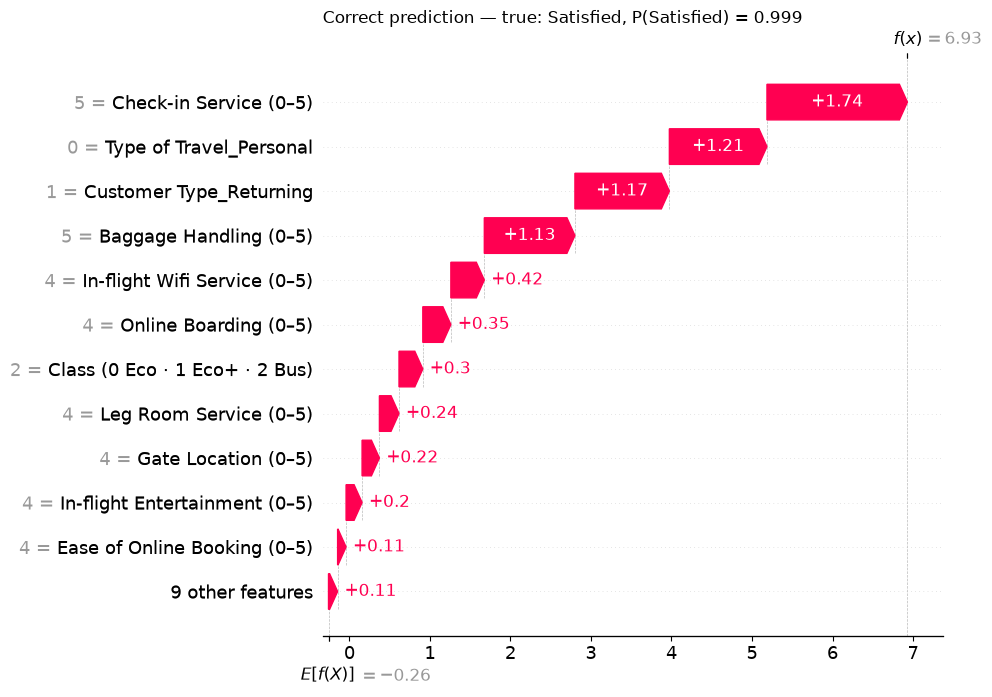

In [15]:
plt.figure()
shap.plots.waterfall(expl_cases[0], max_display=12, show=False)
plt.title(f"Correct prediction — true: {CLASS_NAMES[y_test.iloc[i_right]]}, "
          f"P(Satisfied) = {proba_best[i_right]:.3f}", loc="left")
plt.savefig(FIG_DIR / "week3_shap_waterfall_correct.png", dpi=150, bbox_inches="tight")
plt.show()

**SLOT — interpretation · owner: Kamila.** Explain this passenger's prediction in domain terms: which of their ratings or trip facts pushed the model towards the correct answer, and whether that matches what an airline analyst would expect.

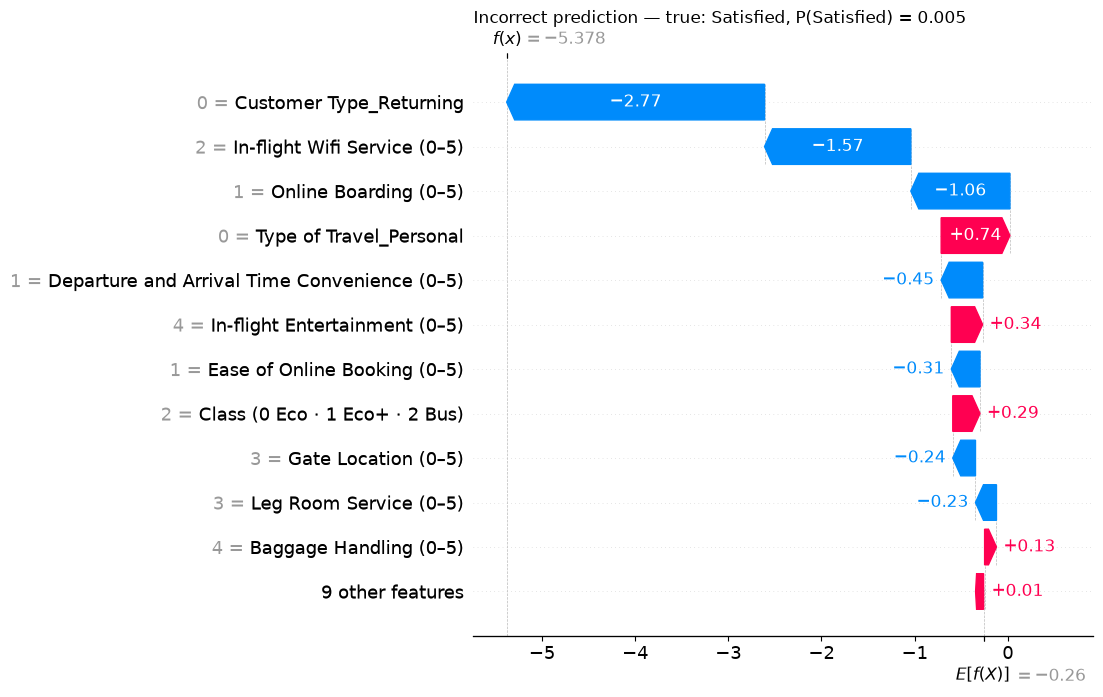

In [16]:
plt.figure()
shap.plots.waterfall(expl_cases[1], max_display=12, show=False)
plt.title(f"Incorrect prediction — true: {CLASS_NAMES[y_test.iloc[i_wrong]]}, "
          f"P(Satisfied) = {proba_best[i_wrong]:.3f}", loc="left")
plt.savefig(FIG_DIR / "week3_shap_waterfall_incorrect.png", dpi=150, bbox_inches="tight")
plt.show()

**SLOT — interpretation · owner: Kamila.** Explain why the model got this passenger wrong with high confidence: which features misled it, whether the passenger's ratings contradict their stated satisfaction (label noise or an experience not captured by the 22 features), and what that implies for the model and for the airline.

## 12. Export the best pipeline for Week 4

The best pipeline (refitted on all of `X_train`) is saved with `joblib` for the Week 4 Streamlit app and reloaded to check that predictions are identical.

In [17]:
MODEL_PATH = MODEL_DIR / "week3_best_pipeline.joblib"
best_pipe.set_params(memory=None)   # the cache is a fit-time detail of this machine; prediction is unchanged
joblib.dump(best_pipe, MODEL_PATH)
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict_proba(X_test), best_pipe.predict_proba(X_test))
print(f"Saved {BEST} -> {MODEL_PATH.relative_to(ROOT)} ({MODEL_PATH.stat().st_size / 1024:.0f} KiB); "
      "reloaded predict_proba identical")
best_pipe

Saved XGBoost (early stopping) -> models\week3_best_pipeline.joblib (4598 KiB); reloaded predict_proba identical


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['Gender','Age','Customer Type',...,'In-flight Wifi Service', 'In-flight Entertainment','Baggage Handling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('class_ord', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that